# 02 — Data checks

This notebook documents every check that shaped the sample and the variable choices
(see `DECISIONS.md`). It reads the raw LSEG files in `data/raw/lseg/` and the
processed panel in `data/processed/`. Run from the repository root.

**Outputs** (`output/tables/`): `coverage_by_year.csv`, `sample_attrition.csv`,
`estimation_method_by_year.csv`, `ppi_coverage.csv`; (`output/figures/`): `coverage_by_year.pdf`.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sample as S

RAW = Path("data/raw/lseg")
TAB, FIG = Path("output/tables"), Path("output/figures")
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

VARS = ["scope1", "scope2", "scope12_total", "scope12_marketbased", "co2_estimation_method",
        "energy_use_total", "energy_purchased", "revenue", "total_assets"]


def load_raw(v):
    d = pd.read_csv(RAW / f"raw_{v}.csv")
    d["date"] = pd.to_datetime(d["date"], errors="coerce")
    d["fyear"] = d["date"].dt.year - (d["date"].dt.month <= 5).astype(int)
    return d.dropna(subset=["value"])

## 1. Coverage by variable and fiscal year
Number of firms (out of 601 STOXX Europe 600 constituents on 31 Dec 2021) with a
non-missing value. This check motivated decisions 2 and 4 in `DECISIONS.md`.

In [2]:
cov = {}
for v in VARS:
    d = load_raw(v)
    cov[v] = d[d.fyear.between(2016, 2024)].groupby("fyear").ric.nunique()
cov = pd.DataFrame(cov).T.fillna(0).astype(int)
cov.to_csv(TAB / "coverage_by_year.csv")
cov

fyear,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0
scope1,381,417,449,501,521,555,564,571,445
scope2,380,412,448,503,522,558,565,572,445
scope12_total,421,448,480,519,535,561,566,573,445
scope12_marketbased,0,1,29,83,168,276,467,520,431
co2_estimation_method,478,513,542,554,561,571,575,578,444
energy_use_total,367,404,429,475,496,513,521,524,415
energy_purchased,358,393,411,458,482,498,503,517,412
revenue,507,510,517,519,523,531,536,536,536
total_assets,568,571,578,580,585,591,597,596,597


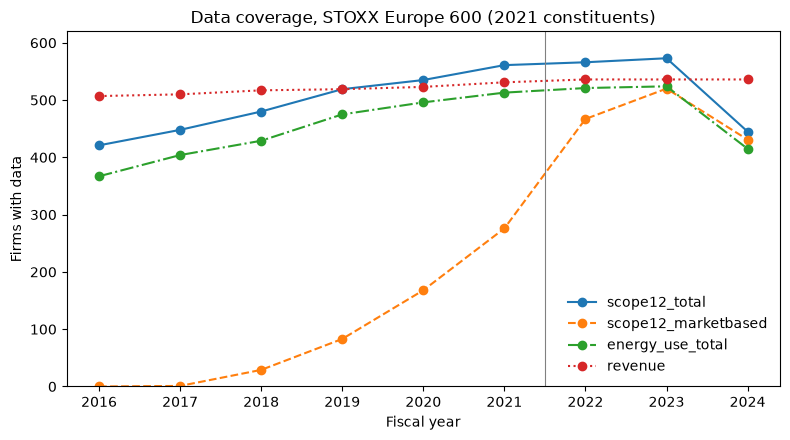

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for v, ls in [("scope12_total", "-"), ("scope12_marketbased", "--"), ("energy_use_total", "-."), ("revenue", ":")]:
    ax.plot(cov.columns, cov.loc[v], ls, marker="o", label=v)
ax.axvline(2021.5, color="grey", lw=0.8)
ax.set_xlabel("Fiscal year"); ax.set_ylabel("Firms with data"); ax.set_ylim(0, 620)
ax.legend(frameon=False); ax.set_title("Data coverage, STOXX Europe 600 (2021 constituents)")
fig.tight_layout(); fig.savefig(FIG / "coverage_by_year.pdf"); plt.show()

**Finding:** market-based Scope 2 is almost absent before 2020, so it cannot support a
pre-trend analysis. Scope 1+2 total is used as the main outcome (decision 4).

## 2. Scope 1+2 total equals Scope 1 + Scope 2

In [4]:
s1, s2, tot = (load_raw(v)[["ric", "fyear", "value"]] for v in ["scope1", "scope2", "scope12_total"])
chk = s1.merge(s2, on=["ric", "fyear"], suffixes=("_s1", "_s2")).merge(tot, on=["ric", "fyear"])
chk = chk[(chk.value_s1 + chk.value_s2) > 0]
ratio = chk.value / (chk.value_s1 + chk.value_s2)
print(f"firm-years: {len(chk)}; share with |ratio-1| < 1%: {(abs(ratio - 1) < 0.01).mean():.3f}")
ratio.describe(percentiles=[.01, .05, .5, .95, .99]).round(3)

firm-years: 5274; share with |ratio-1| < 1%: 0.993


count    5274.000
mean        1.001
std         0.016
min         0.794
1%          1.000
5%          1.000
50%         1.000
95%         1.000
99%         1.000
max         1.530
dtype: float64

## 3. Reported vs. estimated emissions

In [5]:
em = load_raw("co2_estimation_method")
em = em[em.fyear.between(2016, 2024)]
emt = pd.crosstab(em.fyear, em.value)
emt["share_reported"] = (emt["Reported"] / emt.sum(axis=1)).round(3)
emt.to_csv(TAB / "estimation_method_by_year.csv")
emt

value,CO2,Energy,Median,Reported,share_reported
fyear,,,,,
2016.0,10,13,35,420,0.879
2017.0,12,16,38,447,0.871
2018.0,12,11,40,479,0.884
2019.0,5,6,24,520,0.937
2020.0,8,1,17,535,0.954
2021.0,5,1,5,560,0.981
2022.0,3,0,6,566,0.984
2023.0,1,0,4,573,0.991
2024.0,26,0,2,416,0.937


## 4. Fiscal year ends
Fiscal years ending January–May are assigned to the previous calendar year (decision 3).

In [6]:
rev = load_raw("revenue")
rev["date"].dt.month.value_counts().sort_index().rename("firm-years by FY-end month")

date
1       52
2       16
3      408
4       31
5       17
6       68
7       33
8       22
9      152
11      11
12    4889
Name: firm-years by FY-end month, dtype: int64

## 5. Sample attrition

In [7]:
p = S.load_panel()
m = S.main_sample(p)
i = S.industry_sample(p)
static = pd.read_csv(RAW / "raw_static.csv")
ci_any = p.dropna(subset=["ln_ci"])
pre = set(ci_any[ci_any.fyear.isin(S.PRE)].ric); post = set(ci_any[ci_any.fyear.isin(S.POST)].ric)
step_a = ci_any[ci_any.ric.isin(pre & post)]
step_b = step_a[step_a.exposure.notna()]
attr = pd.DataFrame([
    ("STOXX Europe 600 constituents (31 Dec 2021)", static.Instrument.nunique(), np.nan),
    ("Carbon intensity before and after 2022", step_a.ric.nunique(), len(step_a)),
    ("... and pre-crisis energy intensity (2016-2019)", step_b.ric.nunique(), len(step_b)),
    ("... excluding banks and insurers (NACE 64-66) = H1 sample", m.ric.nunique(), len(m)),
    ("... industrial firms (NACE 05-39) with sector PPI = H2 sample", i.ric.nunique(), len(i)),
], columns=["Step", "Firms", "Firm-years"])
attr.to_csv(TAB / "sample_attrition.csv", index=False)
attr

,Step,Firms,Firm-years
0,STOXX Europe 600 constituents (31 Dec 2021),601,NaN
1,Carbon intensity before and after 2022,502,3996.0
2,... and pre-crisis energy intensity (2016-2019),435,3588.0
3,... excluding banks and insurers (NACE 64-66) ...,387,3214.0
4,... industrial firms (NACE 05-39) with sector ...,230,1936.0


## 6. PPI coverage for the H2 sample

In [8]:
ppi_cov = i.drop_duplicates("ric").ppi_source.value_counts().rename("firms")
ppi_cov.to_csv(TAB / "ppi_coverage.csv")
ppi_cov

ppi_source
country          207
EU27 fallback     23
Name: firms, dtype: int64